I import pandas to work with the data and Matplotlib in case I want to make plots later.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


Here I load the raw difficulty file and save a CSV copy in the processed-data folder. I also print the table size and preview a few rows to make sure it loaded as expected.

In [2]:
from pathlib import Path

BASE_DIR = Path("/home/manish-singh/Codes (Linux)/MACHINE LEARNING/ASSIGNMENT/Memory Lab: spaced-repetition-scheduler")

df_diff = pd.read_table(BASE_DIR / "data/raw/opensource_dataset_difficulty.tsv", sep="\t")
df_diff.to_csv(BASE_DIR / "data/processed/difficulty.csv", index=False)

print(df_diff.shape)
df_diff.head()

(17080, 7)


,w,d,t_history,r_history,delta_t,p_recall,total_cnt
0,AIDS,1,0,0,1,0.9760,792
1,Africa,1,0,0,1,0.8592,696
2,African,1,0,0,1,0.9174,363
3,Allah,1,0,0,1,0.9524,105
4,Antarctic,3,0,0,1,0.7874,1176


I look over the table’s size, columns, missing values, example rows, and summary statistics. Then I remove rows with a blank word field and drop exact duplicates.

In [3]:
print(f"Shape: {df_diff.shape[0]:,} rows x {df_diff.shape[1]} columns")
print(f"Unique Words (w): {df_diff['w'].nunique():,}\n")
print(df_diff.info())
print(df_diff.isnull().sum())

display(df_diff.head(10))
display(df_diff.describe())

df_diff = df_diff[(df_diff["w"].astype(str).str.strip() != "")].drop_duplicates()

Shape: 17,080 rows x 7 columns
Unique Words (w): 17,079

<class 'pandas.DataFrame'>
RangeIndex: 17080 entries, 0 to 17079
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   w          17079 non-null  str    
 1   d          17080 non-null  int64  
 2   t_history  17080 non-null  int64  
 3   r_history  17080 non-null  int64  
 4   delta_t    17080 non-null  int64  
 5   p_recall   17080 non-null  float64
 6   total_cnt  17080 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 1.0 MB
None
w            1
d            0
t_history    0
r_history    0
delta_t      0
p_recall     0
total_cnt    0
dtype: int64


,w,d,t_history,r_history,delta_t,p_recall,total_cnt
0,AIDS,1,0,0,1,0.9760,792
1,Africa,1,0,0,1,0.8592,696
2,African,1,0,0,1,0.9174,363
3,Allah,1,0,0,1,0.9524,105
4,Antarctic,3,0,0,1,0.7874,1176
5,Antarctica,3,0,0,1,0.7816,293
6,Arabian,2,0,0,1,0.8392,143
7,Arabic,2,0,0,1,0.8186,204
8,Argentina,2,0,0,1,0.8137,102
9,Arizona,1,0,0,1,0.8505,107


,d,t_history,r_history,delta_t,p_recall,total_cnt
count,17080.000000,17080.0,17080.0,17080.0,17080.000000,17080.000000
mean,5.677518,0.0,0.0,1.0,0.640175,2144.194614
std,2.715804,0.0,0.0,0.0,0.142451,2743.986973
min,1.000000,0.0,0.0,1.0,0.224700,100.000000
25%,4.000000,0.0,0.0,1.0,0.528800,265.000000
50%,6.000000,0.0,0.0,1.0,0.640600,693.000000
75%,8.000000,0.0,0.0,1.0,0.748625,3223.000000
max,10.000000,0.0,0.0,1.0,0.990100,14318.000000


I remove any rows that still have missing values and check the missing-value counts to see what remains.

In [4]:
df_diff = df_diff.dropna()
df_diff.isnull().sum()

w            0
d            0
t_history    0
r_history    0
delta_t      0
p_recall     0
total_cnt    0
dtype: int64

I take one last look at the cleaned table: a few rows, its size, and the column types.

In [5]:
df_diff.head(10)
df_diff.shape
df_diff.info()

<class 'pandas.DataFrame'>
Index: 17079 entries, 0 to 17079
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   w          17079 non-null  str    
 1   d          17079 non-null  int64  
 2   t_history  17079 non-null  int64  
 3   r_history  17079 non-null  int64  
 4   delta_t    17079 non-null  int64  
 5   p_recall   17079 non-null  float64
 6   total_cnt  17079 non-null  int64  
dtypes: float64(1), int64(5), str(1)
memory usage: 1.2 MB


Now I use the saved model to make predictions for the word-history examples in this difficulty table. I build the same 17 input features used during training, then compare each prediction with the table’s `p_recall` estimate. This is a useful sanity check on real examples; it is separate from the unseen-user holdout score because these rows are not the training project’s held-out test split.

In [6]:
import joblib
import numpy as np

model_bundle = joblib.load(BASE_DIR / "models/syllabus_gb_model.joblib")
feature_cols = model_bundle["features"]

feature_rows = []
valid_rows = []
for _, row in df_diff.iterrows():
    t_list = [float(value) for value in str(row["t_history"]).split(",")]
    r_list = [int(value) for value in str(row["r_history"]).split(",")]
    if not t_list or len(t_list) != len(r_list):
        continue
    hist_len = len(r_list)
    recall_count = sum(r_list)
    last_interval = t_list[-1]
    max_interval = max(t_list)
    word = str(row["w"]).strip()
    feature_rows.append({
        "i": hist_len + 1,
        "d": float(row["d"]),
        "delta_t": int(row["delta_t"]),
        "hist_len": hist_len,
        "recall_count": recall_count,
        "lapse_count": hist_len - recall_count,
        "lapse_ratio": (hist_len - recall_count) / hist_len,
        "last_outcome": r_list[-1],
        "recent_3_recall_rate": float(np.mean(r_list[-3:])),
        "last_interval": last_interval,
        "mean_interval": float(np.mean(t_list)),
        "max_interval": max_interval,
        "log_delta_t": float(np.log1p(row["delta_t"])),
        "log_last_interval": float(np.log1p(last_interval)),
        "elapsed_to_last_ratio": float(row["delta_t"]) / (last_interval + 0.1),
        "elapsed_to_max_ratio": float(row["delta_t"]) / (max_interval + 0.1),
        "word_len": len(word),
    })
    valid_rows.append(row)

difficulty_check = pd.DataFrame(valid_rows).reset_index(drop=True)
X_difficulty = pd.DataFrame(feature_rows)[feature_cols]
difficulty_check["model_p_recall"] = model_bundle["model"].predict_proba(X_difficulty.to_numpy())[:, 1]
difficulty_check["absolute_error"] = (difficulty_check["model_p_recall"] - difficulty_check["p_recall"]).abs()
weights = difficulty_check["total_cnt"].to_numpy(dtype=float)
weighted_mae = np.average(difficulty_check["absolute_error"], weights=weights)
print(f"Rows scored: {len(difficulty_check):,} of {len(df_diff):,}")
print(f"Count-weighted mean absolute error vs p_recall: {weighted_mae:.3f}")
display(difficulty_check[["w", "d", "p_recall", "model_p_recall", "total_cnt", "absolute_error"]].head(10).round(3))


Rows scored: 17,079 of 17,079
Count-weighted mean absolute error vs p_recall: 0.014


,w,d,p_recall,model_p_recall,total_cnt,absolute_error
0,AIDS,1,0.976,0.871,792,0.105
1,Africa,1,0.859,0.874,696,0.015
2,African,1,0.917,0.874,363,0.043
3,Allah,1,0.952,0.871,105,0.081
4,Antarctic,3,0.787,0.769,1176,0.019
5,Antarctica,3,0.782,0.771,293,0.011
6,Arabian,2,0.839,0.808,143,0.031
7,Arabic,2,0.819,0.808,204,0.011
8,Argentina,2,0.814,0.808,102,0.006
9,Arizona,1,0.850,0.874,107,0.024


This scatter plot compares the model’s recall probabilities with the reference `p_recall` values. Points close to the diagonal agree more closely. The color shows word difficulty, and the marker size reflects how many observations contributed to each reference value.

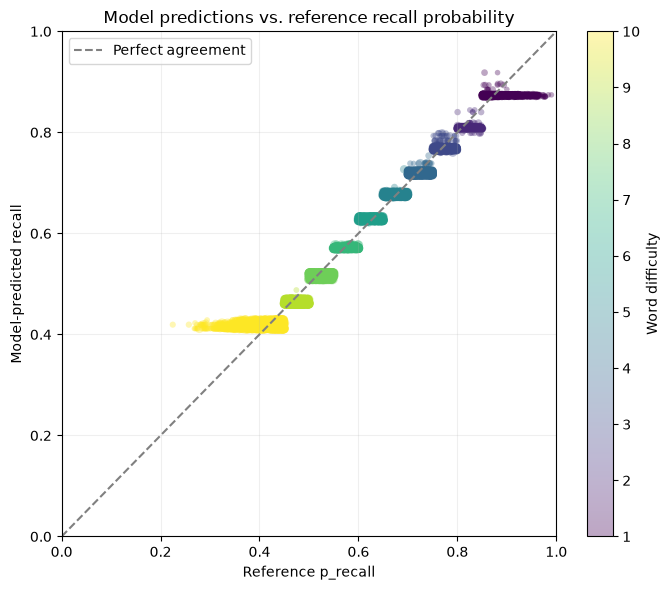

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
sizes = 12 + 48 * np.sqrt(difficulty_check["total_cnt"] / difficulty_check["total_cnt"].max())
points = ax.scatter(
    difficulty_check["p_recall"], difficulty_check["model_p_recall"],
    c=difficulty_check["d"], s=sizes, alpha=0.35, cmap="viridis",
    edgecolors="none"
)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect agreement")
ax.set(
    title="Model predictions vs. reference recall probability",
    xlabel="Reference p_recall", ylabel="Model-predicted recall",
    xlim=(0, 1), ylim=(0, 1),
)
ax.grid(alpha=0.2)
ax.legend()
fig.colorbar(points, ax=ax, label="Word difficulty")
fig.tight_layout()
plt.show()
